# Class 18: Machine Learning 1 — General & Link Prediction

Goal of today's class:
1. Understand, at a high level, how to train and evaluate a classifier
2. Define canonical link prediction tasks, and introduce basic measures for link prediction
3. Fit models for link prediction, and compare them to simple scores we can write by hand
4. See what can go wrong: overfitting, leakage, and measuring the wrong thing

*Content Acknowledgements: Much of the link prediction material in this lesson is adapted from the 2024 final project of [Yixuan Liu](https://github.com/liu-yi-xuan), a PhD student in Network Science at Northeastern University!*
__________

## Getting today's notebook

**Every class, duplicate the notebook before you run anything, and work in the copy.** Running a cell changes the file, and a changed original can block your next pull.

1. Log in to [Open OnDemand](https://ood.explorer.northeastern.edu/), open the **Courses** menu, and click **JupyterLab (Python)**. Launch it with the same settings as last class; they should already be filled in.
2. Once JupyterLab starts, open a terminal (**File → New → Terminal**) and pull the new material, where `USERNAME` is your Northeastern username:
   ```bash
   cd /courses/NETS7052.202710/students/USERNAME/nets7052_fa26
   git fetch upstream
   git checkout main
   git merge --no-edit upstream/main
   ```
   Once you've committed work of your own to your fork (Assignment 1, for example), this merge needs a commit message. `--no-edit` lets Git write that message itself instead of opening a text editor in your terminal.
3. **Duplicate today's notebook before you run anything.** In the file browser, open `notebooks/class_18_machine_learning1/`, right-click `class_18_machine_learning1.ipynb`, and choose **Duplicate**. Open the copy (`class_18_machine_learning1-Copy1.ipynb`) and work there.
4. Check that the top-right corner of the notebook says **Python (cmns-core)**. If it doesn't, choose **Kernel → Change Kernel…** and pick it.

**If the merge doesn't work:**

- *"Your local changes to the following files would be overwritten by merge"*: you changed a notebook that I've since updated, and Git lists which one. If you took notes in it, duplicate it first. Then close it and reset it, using the path Git listed:
  ```bash
  git restore notebooks/class_17_sampling/class_17_sampling.ipynb
  ```

  `git restore` throws away every change you made to that one file and puts back the version from your last pull. Git can't undo it, which is why you duplicate first. Then run `git merge --no-edit upstream/main` again.
- *"'upstream' does not appear to be a git repository"*: you missed a step in Class 0. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote add upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```
- **Git asks for a GitHub username or password:** don't type them. Your `upstream` address is wrong. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote set-url upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```

In [1]:
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score

# White backgrounds for axes, figures and saved files; gridlines drawn behind the data
rc('axes', axisbelow=True, fc='w')
rc('figure', fc='w')
rc('savefig', fc='w')

# One seed for the whole notebook, so the graphs, the train/test splits and the plots come out
# the same every time you run it
SEED = 42

## Basic ML principles

Machine learning basically involves building algorithms that can learn things from data and make generalizations to new data.

Supervised machine learning is the practice of building a model when we have training data (the information that we use to inform our model how the world works) that has correct ground truth answers. When you built a linear regression on the fish data in Class 6, you were doing supervised machine learning, and most of the vocabulary we need today was already there:

| Word | What it means | In the fish regression |
|---|---|---|
| **Features** ($X$) | The columns the model is allowed to look at | Lengths, height, width |
| **Label** ($y$) | The answer we want to predict | Weight |
| **Model** | A family of possible rules | Linear functions of the features |
| **Fitting** (or training) | Picking the rule in the family that does best on the examples | `reg.fit(...)` |
| **Prediction** | Applying the rule to a new example | `reg.predict(...)` |
| **Generalization** | Doing well on examples that played no part in the fitting | We never checked this |

In contrast, unsupervised machine learning is useful when we don't have access to exact ground truths about desired outcomes, but we have to build insights with our dataset anyway. Clustering is one type of unsupervised machine learning technique, and you've done plenty of that with community detection.

Today we're going to focus on supervised ML, specifically *binary classification*. Binary classification involves learning to answer a yes-or-no question about new data points after optimizing a model's parameters using a set of data points with established answers.

### Train/test splits
Training models requires training data and test data at minimum. Our training data is what the model learns patterns from, and the test data tells us how well the model does on data it hasn't seen before.

**If we were to test on the same data we trained on, what could potentially happen?** (We did exactly this with the fish in Class 6.)

----------------
Spoiler: we can get a great score from a model that does badly on anything new, and we'd have no way of knowing. The problem is called **overfitting**. Overfitting happens when your model learns the data it's trained on too well. It's too accustomed to the training data and doesn't generalize well to new data. We might have too many parameters in our model, such that it's able to memorize the quirks of the training set.

We can also get fooled by picking our training set badly. There's an example from a talk about explainability where scientists trained a model to guess where a Google StreetView photo was taken. It did really well on images taken at the same time as other images in the training set and really poorly on images taken at a later date. Turns out that the model was memorizing how windshield smudges changed over time and correlated the state of the windshield smudges to the car's location. So when the smudges changed (but the landscape didn't), the model was not able to identify the locations anymore.

When we construct training and testing sets, we need to make sure the data that we use for training has similar patterns to the test data while keeping the training and testing sets strictly separate from each other.

Our yes-or-no question for today is whether there's an edge between two nodes. Let's start with what that question looks like on a network.

## Introduction to link prediction in networks

In many real-world systems, networks are not static: new ties appear over time (friendships, collaborations, hyperlinks, trade relations), and sometimes ties disappear. Sometimes, the network was collected with errors present, or there is inherent stochasticity or noise in the link formation process. Our basic predictive task, then, is:

> Given a snapshot of a network at time $t$, which pairs of nodes are currently not connected but either likely will be at time $t + \Delta t$ or *should already be but are not through network noise*?

This formulation covers two closely related problems (Liben-Nowell and Kleinberg, 2007; Lü and Zhou, 2011):

* **Future link prediction**, where we treat the current graph as $G(t)$ and try to anticipate edges that will appear at a later time $t + \Delta t$ but are not yet present.
* **Missing link inference**, where we treat the observed network as a noisy or incomplete version of some latent "true" graph and try to infer edges that should exist but were not observed.

In both cases, the core task is to assign a score $s(i,j)$ to each *non-edge* $(i,j)$ and to rank these candidate pairs by how likely they are to be "real" edges under whatever mechanism we believe is shaping the network.

![](images/link_prediction.png)

### A wide range of application areas

* recommendation systems, where we represent users and items as a bipartite graph and predict which missing user-item edges are most likely to appear in the future;
* social and information networks, where we forecast new friendships, citations, or hyperlinks based on the current topology;
* biological networks, where we infer missing protein-protein interactions or regulatory links that are plausible given the observed interaction structure;
* knowledge graphs, where we attempt to fill in missing relationships between entities.

There are two broad ways to attack this. The first treats every node pair as a row in a table. The label is 1 if the pair is an edge and 0 if not, the columns describe the pair (how many neighbors they share, their degrees, ...), and we fit a model that predicts the label, much like the regressions in Class 6 (Al Hasan et al., 2006). The second skips the table and scores pairs straight from the network, either with a simple rule like "count the common neighbors" or by fitting a generative model of the whole network, such as the stochastic block models from the community-detection classes or hierarchical random graphs ([Clauset, Moore, and Newman, 2008](https://www.nature.com/articles/nature06830)). Today we'll start with the simple rules, then fit models on top of them.

_______
#### The plan
- hide some edges of a known graph and see whether a method can find them again (a train/test split);
- write down five classic neighborhood scores: common neighbors, Jaccard, Adamic-Adar, preferential attachment, and resource allocation;
- evaluate them with ROC-AUC and precision at top-$k$;
- fit classifiers that use those scores as features, and see how they can fool us;
- look at a network where these scores fail badly (a disassortative stochastic block model) and see what a model can do about it.

We won't touch graph neural networks today, those are on Monday. These simple scores are the baselines any fancier method has to beat, and you can't judge a fancy method until you know what counting common neighbors already gets you.

### A toy network for link prediction

In practice, link prediction is often studied on longitudinal data: we observe the network at multiple time points $\{G(t_0), G(t_1), \dots\}$ and try to predict which non-edges at time $t_i$ become edges at time $t_{i+1}$. Here we approximate this temporal setting by synthetically hiding a subset of edges.

For clarity, we start with a single undirected, unweighted graph $G$ and treat it as if it were a snapshot at some time $t$. We will use a Barabási-Albert graph as a stylized model of a network with a broad, heavy-tailed degree distribution. This is not necessary for link prediction, but it gives us a simple example where degree heterogeneity matters and where neighborhood-based heuristics are non-trivial.

Recall that the BA model grows the network by repeatedly adding new nodes, each of which connects to $m$ existing nodes with probability proportional to their degree ("preferential attachment"). (Careful with the letter: here $m$ is the BA parameter. Later in the notebook $m$ is the number of edges.) This produces hubs and a skewed degree distribution.

Number of nodes: 200
Number of edges: 591


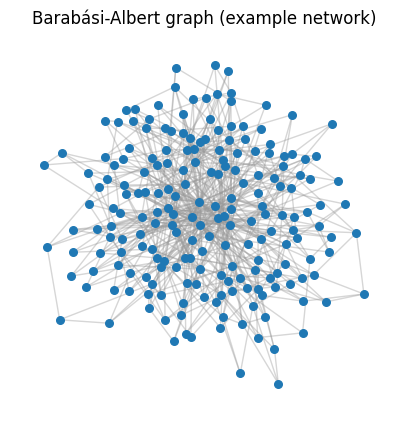

In [2]:
N = 200   # number of nodes
m = 3     # each new node attaches to m existing nodes

G_full = nx.barabasi_albert_graph(N, m, seed=SEED)

print(f"Number of nodes: {G_full.number_of_nodes()}")
print(f"Number of edges: {G_full.number_of_edges()}")

# Fix the layout once; the train/test figure below reuses pos so the nodes stay put
pos = nx.spring_layout(G_full, seed=SEED)


fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=100)
nx.draw_networkx_nodes(G_full, pos, node_size=30, ax=ax)
nx.draw_networkx_edges(G_full, pos, alpha=0.4, edge_color='.6', ax=ax)
ax.set_axis_off()

ax.set_title("Barabási-Albert graph (example network)")

plt.show()

#### ...okay now what (your turn)

Before reading on, write down a plan as comments in the cell below. If all you had was this one graph, how would you build a test that a link-prediction method could pass or fail? What would count as a positive example, and what as a negative one? The next section gives one standard answer.

In [3]:
pass

### Constructing a train/test split by hiding edges

To test a link predictor, we need pairs where we already know the answer: node pairs that *do* become edges and node pairs that *do not*. In truly temporal data we would use two snapshots, $G(t_0)$ and $G(t_1)$, and define positives as edges that appear between $t_0$ and $t_1$. Today we approximate this setting by **hiding** a random subset of edges from a single static graph.

The basic idea is:
1. Start from the original graph $G = (V, E)$.
2. Randomly select a fraction of existing edges to hold out as a **test set**, $E_{\text{test}} \subset E$.
3. Remove these edges from the graph to obtain a **training graph**, $ G_{\text{train}} = (V, E_{\text{train}})$ with $ E_{\text{train}} = E \setminus E_{\text{test}} $.
4. Treat each $(i, j) \in E_{\text{test}}$ as a *positive* example for evaluation.
5. Sample the same number of node pairs that are non-edges in the original graph $G$. Call this set $\mathcal{N}_{\text{test}}$; these are the *negative* examples.

All link prediction scores in this first part will be computed on $G_{\text{train}}$. 

**The evaluation task is then: using only $G_{\text{train}}$, assign higher scores to the hidden edges in $E_{\text{test}}$ than to the sampled non-edges.**

**Note:** One subtlety is connectivity. If we remove edges arbitrarily, we may disconnect $G_{\text{train}}$ in ways that make the task less realistic or break methods that assume a single connected component. To avoid this, our splitting function can optionally avoid removing bridges (aka edges whose removal would disconnect the graph). When `ensure_connected=True`, we only hide non-bridge edges, so that $G_{\text{train}}$ remains connected.


The helper function below wraps all of this into a single call:

- Input: an undirected simple graph `G`, the fraction of edges to hide (`test_frac`), a random seed, and `ensure_connected` (skip bridges so `G_train` stays connected, assuming `G` starts out connected).
- Output:
  - `G_train`: the training graph with some edges removed,
  - `test_edges`: the list of hidden edges (positives),
  - `test_non_edges`: a sampled list of non-edges (negatives) of the same size.

We will reuse this function throughout today's class to generate consistent train/test splits for different graphs and methods.

In [4]:
def train_test_split_graph(G, test_frac=0.2, seed=5, ensure_connected=True):
    """
    Create a train/test split of edges for link prediction.

    Parameters
    ----------
    G : nx.Graph
        Original undirected graph (assumed simple).
    test_frac : float
        Target fraction of edges to hide for testing (between 0 and 1).
    seed : int
        Random seed for reproducibility.
    ensure_connected : bool
        If True, avoid removing edges that would disconnect the training graph.
        If there are not enough non-bridge edges, fewer than test_frac * |E|
        edges will be removed.

    Returns
    -------
    G_train : nx.Graph
        Training graph with some edges removed.
    test_edges : list of (i, j)
        Edges that were removed and will be used as positive test examples.
    test_non_edges : list of (i, j)
        Node pairs that are not edges in the original graph, used as
        negative examples.
    """
    rng_local = np.random.default_rng(seed)

    # Work on a copy so we never mutate the original input graph
    G_train = G.copy()
    all_edges = list(G_train.edges())
    n_edges = len(all_edges)

    # Number of edges we will try to hide (may be fewer if we run out
    # of non-bridge edges when ensure_connected=True)
    n_test = int(test_frac * n_edges)

    # Randomize edge order so the choice of hidden edges is uniform-ish
    rng_local.shuffle(all_edges)
    test_edges = []

    if ensure_connected:
        # Remove edges one by one, skipping bridges to keep G_train connected
        for (i, j) in all_edges:
            if len(test_edges) >= n_test:
                break

            # Bridges change as we remove edges, so we recompute them each time
            # (fine for small/medium graphs; this is a teaching function)
            bridges = set(nx.bridges(G_train)) if nx.has_bridges(G_train) else set()

            # If this edge is currently a bridge, skip it to avoid disconnecting
            if (i, j) in bridges or (j, i) in bridges:
                continue

            # Otherwise, remove the edge and record it as a positive test example
            G_train.remove_edge(i, j)
            test_edges.append((i, j))
        # Note: if there are not enough non-bridge edges, test_edges may end up
        # shorter than n_test; we handle that naturally below.
    else:
        # Simple random edge hold-out: remove the first n_test shuffled edges
        test_edges = all_edges[:n_test]
        G_train.remove_edges_from(test_edges)

    # Sample negative examples (non-edges) from the *original* graph G.
    # Using G (not G_train) guarantees we never accidentally choose a hidden
    # positive edge as a "negative" example.
    non_edges = list(nx.non_edges(G))
    rng_local.shuffle(non_edges)

    # Take as many negatives as there are positives, so the test set is balanced
    test_non_edges = non_edges[: len(test_edges)]

    return G_train, test_edges, test_non_edges

In [5]:
G_train, test_edges, test_non_edges = train_test_split_graph(G_full, test_frac=0.2,
                                                     seed=SEED, ensure_connected=True)

print(f"Original graph edges: {G_full.number_of_edges()}")
print(f"Training graph edges: {G_train.number_of_edges()}")
print(f"Number of positive test edges: {len(test_edges)}")
print(f"Number of negative test non-edges: {len(test_non_edges)}")
print(f"Is G_train connected? {nx.is_connected(G_train)}")

Original graph edges: 591
Training graph edges: 473
Number of positive test edges: 118
Number of negative test non-edges: 118
Is G_train connected? True


Sanity check: 20% of 591 is 118.2, so we hide 118 edges, and 591 − 118 = 473 stay in `G_train`. It's still connected, and we have 118 non-edges to match the 118 hidden edges.

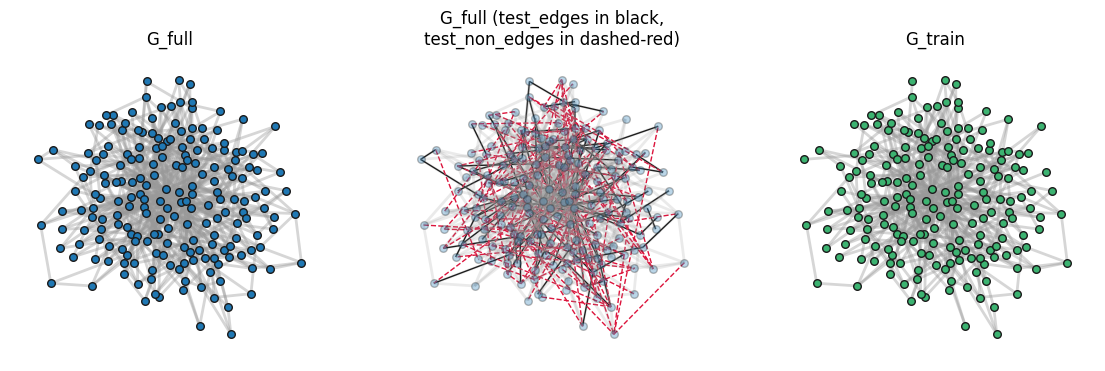

In [6]:
# A graph whose only edges are the sampled non-edges, so we can draw them (dashed red) in the middle panel below
non_G_plotting = nx.Graph()
non_G_plotting.add_nodes_from(G_full.nodes())
non_G_plotting.add_edges_from(test_non_edges)

fig, ax = plt.subplots(1,3,figsize=(14,4),dpi=100)

nx.draw_networkx_nodes(G_full, pos, node_size=30, ax=ax[0], edgecolors='.1')
nx.draw_networkx_edges(G_full, pos, alpha=0.4, edge_color='.6', ax=ax[0], width=2)
ax[0].set_axis_off()
ax[0].set_title("G_full")

nx.draw_networkx_edges(G_full, pos, edgelist=test_edges, edge_color='k', ax=ax[1], width=1)
nx.draw_networkx_edges(non_G_plotting, pos, edgelist=test_non_edges,
                       edge_color='crimson', ax=ax[1], width=1, style='--')
nx.draw_networkx_nodes(G_full, pos, node_size=30, ax=ax[1], alpha=0.3, edgecolors='.1')
nx.draw_networkx_edges(G_full, pos, alpha=0.2, edge_color='.6', ax=ax[1], width=2)
ax[1].set_axis_off()
ax[1].set_title("G_full (test_edges in black,\ntest_non_edges in dashed-red)")


nx.draw_networkx_nodes(G_train, pos, node_size=30, node_color='mediumseagreen', edgecolors='.1', ax=ax[2])
nx.draw_networkx_edges(G_train, pos, alpha=0.4, edge_color='.6', ax=ax[2], width=2)
ax[2].set_axis_off()
ax[2].set_title("G_train")



plt.show()

Many of the black hidden edges touch the hubs. A hub has lots of edges, so when we pick edges at random it's likely to lose one. The dashed red non-edges are picked uniformly from all pairs, so most of them join two low-degree nodes. Keep this in mind when we get to preferential attachment.

## Extended note: Class imbalance in link prediction

A structural feature of link prediction problems is that they are **extremely imbalanced**. Here a "class" just means a label: edge or non-edge. In a simple undirected graph with $n$ nodes, there are

$$
\binom{n}{2} = \frac{n(n-1)}{2}
$$

possible node pairs. Only $m$ of these pairs are observed edges; the rest are non-edges. In most real networks $m \ll \binom{n}{2}$, so the fraction of pairs that are connected is tiny.

For example, if $n = 10^5$ and $m = 10^6$, then:

* the number of possible pairs is about $5 \times 10^{9}$,
* the edge density $m / \binom{n}{2}$ is about $2 \times 10^{-4}$,
* for every positive (an actual or future edge) there are about five thousand negatives (pairs that never connect).

### Why we artificially balance positives and negatives

For most of today, we build balanced test sets by:

* hiding a subset of edges as positives (for example, $|E_{\text{test}}|$ edges), and
* sampling an equal number of non-edges as negatives.

This artificial balancing is useful for teaching and small-scale experiments:

1. It keeps the dataset size manageable: we do not need to score all $O(n^2)$ non-edges.
2. It avoids trivial baselines that achieve nearly perfect accuracy by predicting "no edge" almost everywhere.
3. It gives a fixed reference point: on a balanced set, a random ranking scores about 0.5 on both ROC-AUC and precision@$k$ (both defined below).

The two metrics react differently to balancing, though. ROC-AUC compares positives with negatives one pair at a time, so it does not depend on how many negatives there are: with uniformly sampled negatives it estimates the AUC we would get on all non-edges. Precision@$k$ and average precision (we'll define both later) do depend on the ratio, and on all non-edges of a sparse graph they are far lower than on a balanced set.

### Why *accuracy* is misleading

Consider a classifier that predicts "no link" for every candidate pair: if we evaluate it on all pairs $(i,j)$, its accuracy is extremely high (close to 1), because almost all pairs are non-edges... but it is useless for link prediction, because it never finds any new edges.

Even on balanced test sets, accuracy can be a weak indicator of ranking quality. This is why link prediction work typically reports ranking metrics (ROC-AUC, precision@$k$, average precision) rather than raw accuracy. More on this soon!

Because we rarely evaluate on all non-edges, we must decide which *negatives to sample*. Different choices answer different questions:

* Uniform negative sampling asks whether the method can separate future edges from "typical" non-edges.
* Popularity- or exposure-aware sampling is common in recommendation systems, where not all non-edges are equally "negative".

The final numerical value of ROC-AUC or precision@$k$ should always be interpreted relative to how the negative examples were constructed.
_____________

## Let's predict some missing links!
... okay, how?

### Classical neighborhood-based link prediction scores

Most of the classic link predictors start from one idea:

> Two nodes are more likely to form a link if they have many neighbors in common or if they are embedded in similar local neighborhoods.

In social networks, this is the notion of *triadic closure* (i.e., the "friends of my friends are likely to become my friends.") In other domains, it corresponds to functional similarity (two neurons that interact with many of the same partners may be part of the same cluster) or topical relatedness (two web pages that are connected by many others may cover similar content).

For an undirected graph, let $\Gamma(i)$ denote the set of neighbors of node $i$, and let $k_i = |\Gamma(i)|$ be its degree. The simplest neighborhood-based link prediction scores are functions of overlaps between $\Gamma(i)$ and $\Gamma(j)$ and the degrees of $i$, $j$, and their common neighbors. **THERE ARE SO MANY LINK PREDICTION ALGORITHMS,** but let's focus on five canonical ones here.

1. **Common neighbors (CN)**
    The most direct measure simply counts how many neighbors $i$ and $j$ share:

    $$
    s_{\text{CN}}(i, j) = |\Gamma(i) \cap \Gamma(j)|
    $$
    
    This implements the pure triadic-closure intuition: the more common neighbors two nodes have, the more opportunities there have been for a link to form between them. In early empirical work on co-authorship networks, Liben-Nowell and Kleinberg (2007) found that common neighbors alone can already perform surprisingly well.

2. **Jaccard coefficient**
    Common neighbors can be biased toward high-degree nodes: two hubs may share many neighbors simply because they each have many neighbors. The **Jaccard coefficient** normalizes by the size of the union:

    $$
    s_{\text{Jaccard}}(i, j)
    = \frac{|\Gamma(i) \cap \Gamma(j)|}{|\Gamma(i) \cup \Gamma(j)|}
    $$
    
    This is identical to the Jaccard similarity from information retrieval, applied to neighbor sets. It assigns a high score only when the shared neighbors form a large *fraction* of the nodes' combined neighborhoods, not just a large absolute count.

3. **Adamic-Adar index (AA)**
   The **Adamic-Adar index** (Adamic and Adar, 2003) refines common neighbors by downweighting common neighbors that are themselves very high-degree hubs:

   $$
   s_{\text{AA}}(i, j)
   = \sum_{l \in \Gamma(i) \cap \Gamma(j)} \frac{1}{\log k_l}
   $$

   The idea is that a common neighbor $l$ that is connected to *everyone* carries less specific information about similarity between $i$ and $j$ than a rare, low-degree neighbor. Every common neighbor $l$ is linked to both $i$ and $j$, so $k_l \ge 2$ and $\log k_l > 0$: the formula never divides by zero. The logarithm makes the penalty grow slowly with degree: a common neighbor of degree 100 counts about 0.15 times as much as one of degree 2 ($1/\ln 100 \approx 0.22$ against $1/\ln 2 \approx 1.44$).

4. **Preferential attachment (PA)**
    The **preferential attachment** score uses only the degrees of $i$ and $j$:
    
    $$
    s_{\text{PA}}(i, j) = k_i\,k_j
    $$
    
    This is motivated by preferential attachment (Albert and Barabási, 2002): high-degree nodes gain new neighbors faster. In scientific collaboration networks, the chance that two scientists start co-authoring grows with the product of their numbers of collaborators (Newman, 2001; Barabási et al., 2002). The BA model itself is a bit different: every new edge has a newcomer at one end, so in the model hubs gain edges from newcomers, not from each other. Unlike the previous scores, PA does *not* look at common neighbors at all; it purely encodes the rich-getting-richer effect.

5. **Resource allocation index (RA)**
    The **resource allocation** index (Zhou, Lü, and Zhang, 2009) is similar in spirit to Adamic-Adar but uses a $1/k_l$ penalty instead of $1/\log k_l$:

    $$
    s_{\text{RA}}(i, j)
    = \sum_{l \in \Gamma(i) \cap \Gamma(j)} \frac{1}{k_l}
    $$
    
    This can be interpreted as a simple diffusion or resource-sharing process: imagine each common neighbor $l$ has one unit of "resource" and distributes it equally among its neighbors. The amount of resource that flows from $i$ to $j$ via $l$ is then $1/k_l$. Summing over all common neighbors measures how much resource $i$ could send to $j$ through paths of length two. Compared to Adamic-Adar, the $1/k_l$ penalty is stronger for high-degree nodes: a common neighbor of degree 100 counts $2/100 = 0.02$ times as much as one of degree 2, against 0.15 under Adamic-Adar. So RA emphasizes rare, low-degree common neighbors even more.

All five scores are **local**: they depend only on the immediate neighborhoods of $i$ and $j$. Four of them (all but preferential attachment) give higher scores to pairs whose neighborhoods overlap; PA gives two hubs a high score even if they share no neighbors. They are symmetric in $i$ and $j$, and they can be computed for any non-edge $(i,j)$ without fitting a global model.

These are the standard baselines in the field, and they often hold their own against much more complicated methods (Liben-Nowell and Kleinberg, 2007; Lü and Zhou, 2011; Zhou, Lü, and Zhang, 2009). Let's look at each one as a Python function.

Tiny graph time. Nodes $i$ and $j$ have two common neighbors: $a$, which has degree 2 (it only knows $i$ and $j$), and $h$, a hub with degree 10. Say $k_i = 3$ and $k_j = 4$, so $|\Gamma(i) \cup \Gamma(j)| = 5$. Then CN $= 2$, Jaccard $= 2/5 = 0.4$, AA $= 1/\log 2 + 1/\log 10 \approx 1.44 + 0.43 = 1.88$, RA $= 1/2 + 1/10 = 0.6$, and PA $= 3 \times 4 = 12$. Most of AA and RA comes from $a$, the neighbor nobody else knows.

Here are all five. If you want the practice, Class 10 has these as an exercise.

In [7]:
def common_neighbors_score(G, i, j):
    """
    Compute the common-neighbors score between nodes i and j.

    s_CN(i, j) = |Γ(i) ∩ Γ(j)|,

    where Γ(i) is the set of neighbors of i.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Number of common neighbors between i and j.
    """
    # Neighbor sets of each node
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))

    # Intersection of neighbor sets
    common = neighbors_i & neighbors_j

    return float(len(common))


def jaccard_score(G, i, j):
    """
    Compute the Jaccard coefficient between nodes i and j.

    s_Jaccard(i, j) = |Γ(i) ∩ Γ(j)| / |Γ(i) ∪ Γ(j)|.

    If both nodes have no neighbors (empty union), the score is defined as 0.0.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Jaccard similarity between the neighbor sets of i and j.
    """
    # Neighbor sets of each node
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))

    # Intersection and union of neighbor sets
    intersection = neighbors_i & neighbors_j
    union = neighbors_i | neighbors_j

    # If both nodes are isolated, define similarity to be 0
    if not union:
        return 0.0

    return len(intersection) / len(union)


def adamic_adar_score(G, i, j):
    """
    Compute the Adamic-Adar index between nodes i and j.

    s_AA(i, j) = sum_{l in Γ(i) ∩ Γ(j)} 1 / log(k_l),

    where k_l is the degree of the common neighbor l.
    A common neighbor is linked to both i and j, so k_l >= 2 and log(k_l) > 0.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Adamic-Adar score between i and j.
    """
    # Neighbor sets and common neighbors
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))
    common_neighbors = neighbors_i & neighbors_j

    score = 0.0

    # Accumulate 1 / log(k_l) across common neighbors
    for ell in common_neighbors:
        k_ell = G.degree[ell]
        # k_ell >= 2 for any common neighbor, so the log is positive; the check is only a guard
        if k_ell > 1:
            score += 1.0 / np.log(k_ell)

    return score


def preferential_attachment_score(G, i, j):
    """
    Compute the preferential-attachment score between nodes i and j.

    s_PA(i, j) = k_i * k_j,

    where k_i and k_j are the degrees of i and j.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Preferential-attachment score between i and j.
    """
    k_i = G.degree[i]
    k_j = G.degree[j]

    return float(k_i * k_j)


def resource_allocation_score(G, i, j):
    """
    Compute the resource allocation (RA) index between nodes i and j.

    s_RA(i, j) = sum_{l in Γ(i) ∩ Γ(j)} 1 / k_l,

    where k_l is the degree of the common neighbor l.

    Parameters
    ----------
    G : networkx.Graph
        Undirected simple graph.
    i, j
        Node identifiers.

    Returns
    -------
    float
        Resource-allocation score between i and j.
    """
    # Neighbor sets and common neighbors
    neighbors_i = set(G.neighbors(i))
    neighbors_j = set(G.neighbors(j))
    common_neighbors = neighbors_i & neighbors_j

    score = 0.0

    # Accumulate 1 / k_l across common neighbors
    for ell in common_neighbors:
        k_ell = G.degree[ell]
        if k_ell > 0:
            score += 1.0 / k_ell

    return score

_______

#### What do these scores even look like?
Let's start by looking at the Jaccard scores of the hidden edges (positives) and of the sampled non-edges (negatives)...

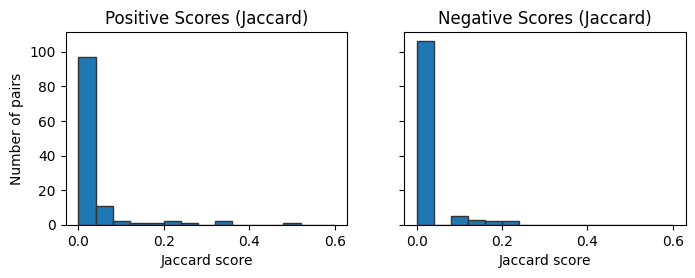

In [8]:
# Jaccard score of every hidden edge, computed on the training graph
pos_scores_jac = [jaccard_score(G_train, i, j) for (i, j) in test_edges]

# ...and of every sampled non-edge
neg_scores_jac = [jaccard_score(G_train, i, j) for (i, j) in test_non_edges]

fig, ax = plt.subplots(1,2,figsize=(8,2.5),dpi=100,sharex=True,sharey=True)

# Jaccard is between 0 and 1; the largest score on this split is 0.5, so bins up to 0.6 cover everything
bins = np.linspace(0, 0.6, 16)
ax[0].hist(pos_scores_jac, bins=bins, ec='.2')
ax[1].hist(neg_scores_jac, bins=bins, ec='.2')
ax[0].set_xlabel('Jaccard score'); ax[1].set_xlabel('Jaccard score'); ax[0].set_ylabel('Number of pairs')

ax[0].set_title('Positive Scores (Jaccard)')
ax[1].set_title('Negative Scores (Jaccard)')

plt.show()

Both panels have a tall bar at zero. Most pairs, hidden edge or not, share no neighbors at all in `G_train`, so their Jaccard score is exactly 0. In this graph that is true of 70% of the hidden edges and 89% of the sampled non-edges. Whatever separation Jaccard achieves comes from the minority of pairs with a nonzero score.

### Evaluating a scoring function

Once we define a link-prediction score $s(i, j)$, we need a way to quantify how well it separates true future edges from non-edges. Given a training graph $G_{\text{train}}$, a set of hidden **positive** edges (the test edges), and a set of sampled **negative** pairs (non-edges), we can:

1. compute a score for each positive and negative example using our chosen function `score_fn(G, i, j)`,
2. build a label vector with 1 for positives and 0 for negatives,
3. compare the scores with the labels using ROC-AUC (defined just below).

The helper function below wraps this pattern: it takes a training graph, lists of positive and negative pairs, and a scoring function, and returns the labels, the scores, and the ROC-AUC value (optionally printing it as well). We will reuse this for all of the neighborhood-based scores today.

#### Evaluation Technique: ROC-AUC 

Given a score function $s(i, j)$, we can evaluate it on our labeled examples:

* For each positive test edge $(i, j) \in E_{\text{test}}$, compute its score.
* For each negative test pair $(i, j) \in \mathcal{N}_{\text{test}}$ (sampled non-edges), compute its score.

Ideally, a hidden edge gets a higher score than a non-edge most of the time.

To draw the ROC curve, pick a threshold $\tau$ and call every pair with $s(i,j) > \tau$ an edge. The **true positive rate** (TPR) is the fraction of hidden edges above $\tau$, and the **false positive rate** (FPR) is the fraction of non-edges above $\tau$. Sliding $\tau$ from very high to very low traces a curve from $(0,0)$ to $(1,1)$, and ROC-AUC is the area under it (Fawcett, 2006). The AUC has a useful interpretation:

> The AUC is the probability that a randomly chosen positive example receives a higher score than a randomly chosen negative example, counting ties as half: $\text{AUC} = P(s_+ > s_-) + \tfrac{1}{2} P(s_+ = s_-)$.

A small example: three hidden edges score 3, 2, 0 and three non-edges score 1, 0, 0. Of the 9 positive-negative pairs, the 3 and the 2 each beat all three non-edges (6 wins), and the 0 loses to the 1 and ties the two 0s (two half-wins). So AUC $= (6+1)/9 = 0.78$. Sanity check: `roc_auc_score([1,1,1,0,0,0], [3,2,0,1,0,0])` gives 0.778. Ties will matter a lot below, because many pairs share no neighbors and score exactly 0.

An AUC of $0.5$ corresponds to random guessing; an AUC of $1.0$ is perfect ranking.

__________

In [9]:
def evaluate_score_function(G_train, test_edges, test_non_edges, score_fn, verbose=True):
    """
    Evaluate a link-prediction scoring function using ROC-AUC.

    Parameters
    ----------
    G_train : networkx.Graph
        Training graph used to compute scores.
    test_edges : list of (i, j)
        Positive examples (edges that were removed from the original graph).
    test_non_edges : list of (i, j)
        Negative examples (node pairs that are non-edges in the original graph).
    score_fn : callable
        Function of the form score_fn(G, i, j) -> float.
    verbose : bool, optional
        If True, print the AUC value.

    Returns
    -------
    y_true : numpy.ndarray
        Labels: 1 for each pair in test_edges, then 0 for each pair in test_non_edges.
    y_scores : numpy.ndarray
        score_fn applied to the same pairs in the same order (positives first).
    auc : float
        ROC-AUC value.
    """
    # Scores for positive examples
    pos_scores = [score_fn(G_train, i, j) for (i, j) in test_edges]

    # Scores for negative examples
    neg_scores = [score_fn(G_train, i, j) for (i, j) in test_non_edges]

    # True labels: 1 for positives, 0 for negatives
    y_true = np.array([1] * len(pos_scores) + [0] * len(neg_scores))

    # Concatenate scores in the same order as labels
    y_scores = np.array(pos_scores + neg_scores)

    # Compute ROC-AUC
    auc = roc_auc_score(y_true, y_scores)

    if verbose:
        print(f"AUC = {auc:.3f}")

    return y_true, y_scores, auc

In [10]:
print("BA graph: Common neighbors:")
y_cn, scores_cn, auc_cn = evaluate_score_function(
    G_train, test_edges, test_non_edges, common_neighbors_score
)
print()
print("BA graph: Jaccard:")
y_jac, scores_jac, auc_jac = evaluate_score_function(
    G_train, test_edges, test_non_edges, jaccard_score
)

print()
print("BA graph: Adamic-Adar:")
y_aa, scores_aa, auc_aa = evaluate_score_function(
    G_train, test_edges, test_non_edges, adamic_adar_score
)

print()
print("BA graph: Preferential attachment:")
y_pa, scores_pa, auc_pa = evaluate_score_function(
    G_train, test_edges, test_non_edges, preferential_attachment_score
)

print()
print("BA graph: Resource allocation:")
y_ra, scores_ra, auc_ra = evaluate_score_function(
    G_train, test_edges, test_non_edges, resource_allocation_score
)

BA graph: Common neighbors:
AUC = 0.596

BA graph: Jaccard:
AUC = 0.585

BA graph: Adamic-Adar:
AUC = 0.592

BA graph: Preferential attachment:
AUC = 0.673

BA graph: Resource allocation:
AUC = 0.592


Preferential attachment has the highest AUC, mostly because of how we built the test set rather than how the BA model grows. A hidden edge is a randomly chosen edge, and a randomly chosen edge is much more likely to touch a hub than a randomly chosen pair is. Here the average $k_i k_j$ is about 60 for the hidden edges and about 19 for the sampled non-edges. Any graph with hubs hands PA this advantage. (Change `SEED` and rerun: for seeds 0 through 99, PA comes out on top every time.) The four neighborhood scores sit close to 0.6, barely above guessing. That's the zero bar from the histograms again. Each new node in this BA graph brings only 3 edges, so few triangles form, and most positives and negatives tie at a score of 0. ROC-AUC counts each tied positive-negative pair as half right.

## Ranking quality and precision at top-$k$

In many applications, we are not forced to classify all candidate pairs. Instead, we only act on the highest-scoring predictions, such as:

* recommending the top 10 new friends to each user,
* suggesting the top 50 potential collaboration links,
* prioritizing the top 100 candidate interactions for experimental validation.

In these scenarios, **precision at top-$k$** is often more meaningful than AUC. For a given $k$:

1. Sort the candidate pairs by their scores in descending order (breaking ties at random).
2. Take the top $k$ pairs.
3. Compute

$$
\text{Precision@}k = \frac{\text{number of true edges among the top } k \text{ pairs}}{k}.
$$

High precision at small $k$ indicates that the method is very good at identifying the most promising candidates.

One thing to keep in mind below: our "candidate pairs" are the balanced test set, the hidden edges plus an equal number of sampled non-edges. Half of them are positives, so a method that ranks pairs at random already gets a precision@$k$ of about 0.5. On the full set of non-edges, where positives are rare, the same method would score far lower.

In [11]:
def precision_at_k(y_true, y_scores, k, seed=0):
    """
    Compute precision at top-k.

    Ties are broken at random (with a fixed seed). Many of our scores are exactly
    0 for most pairs, and without this the order in which we happened to list the
    pairs (positives first) would decide who makes the top k.

    Parameters
    ----------
    y_true : array-like
        True labels (1 for positive, 0 for negative).
    y_scores : array-like
        Scores for each example (higher means more likely positive).
    k : int
        Number of top predictions to consider.
    seed : int, optional
        Seed for the random tie-breaking.

    Returns
    -------
    float
        Fraction of the top-k scored examples that are actually positive.
    """
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    if k <= 0:
        raise ValueError("k must be positive")

    # Do not ask for more than we have
    k = min(k, len(y_true))

    # Shuffle first, then sort by score with a stable sort: pairs with equal
    # scores stay in the shuffled (random) order
    rng_ties = np.random.default_rng(seed)
    perm = rng_ties.permutation(len(y_scores))
    idx_sorted = perm[np.argsort(-y_scores[perm], kind="stable")]

    # Take the top-k indices and compute the fraction that are positive
    topk_idx = idx_sorted[:k]

    return y_true[topk_idx].sum() / k

In [12]:
# Precision@k for each method at a few values of k (random ranking would give about 0.5)
ks = [5, 10, 20, 50]

methods = {
    "Common neighbors": (y_cn, scores_cn),
    "Jaccard": (y_jac, scores_jac),
    "Adamic-Adar": (y_aa, scores_aa),
    "Preferential attachment": (y_pa, scores_pa),
    "Resource allocation": (y_ra, scores_ra),
}

for name, (y, scores) in methods.items():
    print(f"\n{name}:")
    for k in ks:
        p_at_k = precision_at_k(y, scores, k)
        print(f"  Precision@{k:2d} = {p_at_k:.3f}")


Common neighbors:
  Precision@ 5 = 0.800
  Precision@10 = 0.900
  Precision@20 = 0.800
  Precision@50 = 0.720

Jaccard:
  Precision@ 5 = 1.000
  Precision@10 = 0.700
  Precision@20 = 0.450
  Precision@50 = 0.720

Adamic-Adar:
  Precision@ 5 = 0.800
  Precision@10 = 0.900
  Precision@20 = 0.700
  Precision@50 = 0.720

Preferential attachment:
  Precision@ 5 = 1.000
  Precision@10 = 1.000
  Precision@20 = 0.900
  Precision@50 = 0.840

Resource allocation:
  Precision@ 5 = 1.000
  Precision@10 = 0.800
  Precision@20 = 0.650
  Precision@50 = 0.720


Preferential attachment stays near the top at every $k$. The four neighborhood scores bunch together by $k = 50$, because only 48 of the 236 test pairs share any neighbor in `G_train` (35 hidden edges and 13 non-edges). Past the top 48, every neighborhood score is choosing among pairs tied at 0, and `precision_at_k` breaks those ties at random.

__________
## Okay, now let's actually learn something

Everything so far was a hand-built score. Somebody decided that common neighbors matter and wrote down a formula, and that formula never changes no matter what data we show it.

We can also use binary classifiers for link prediction. We already have everything we need for a table. Each row is a node pair, the features are our five scores, and the label says whether the pair is an edge. Then we let a model figure out how much to trust each score.

We'll make one change first. The BA graph was handy for seeing how all of this works, but it has so few triangles that the neighborhood scores were barely above guessing. Let's move to a network you know, the political blogs from Adamic and Glance (2005). We'll treat each hyperlink as an undirected edge and keep the largest connected component.

In [13]:
nodes = pd.read_csv('data/polblogs_nodes_class.tsv', sep='\t', header=None, names=['id', 'blog', 'party'])
edges = pd.read_csv('data/polblogs_edges_class.tsv', sep='\t', header=None, names=['source', 'target'])

G_all = nx.Graph()
G_all.add_edges_from(edges.to_numpy().tolist())
G_all.remove_edges_from(list(nx.selfloop_edges(G_all)))
G_blogs = G_all.subgraph(max(nx.connected_components(G_all), key=len)).copy()

blog_name = dict(zip(nodes['id'], nodes['blog']))
party = dict(zip(nodes['id'], nodes['party']))   # 0 = liberal, 1 = conservative

n_blogs = G_blogs.number_of_nodes()
n_links = G_blogs.number_of_edges()
n_pairs = n_blogs * (n_blogs - 1) // 2

print(f'{n_blogs} blogs, {n_links} edges')
print(f'{n_pairs} possible pairs, of which {n_pairs - n_links} are not edges')
print(f'{(n_pairs - n_links) / n_links:.1f} non-edges for every edge')
print(f'Accuracy if we always say "no edge": {(n_pairs - n_links) / n_pairs:.3f}')

1222 blogs, 16714 edges
746031 possible pairs, of which 729317 are not edges
43.6 non-edges for every edge
Accuracy if we always say "no edge": 0.978


This is the accuracy problem from earlier, now on real data. A classifier that says "no edge" every single time is right about 98% of the time and never finds an edge.

Let's hide 10% of the edges with the same function as before, and see how our five scores do here.

In [14]:
def plot_roc_curves(y_true, score_dict, title):
    """
    Draw one ROC curve per method on a single set of axes.

    Parameters
    ----------
    y_true : numpy.ndarray of 0/1
        Labels shared by every method (1 = hidden edge, 0 = sampled non-edge).
    score_dict : dict
        Maps a method name to its array of scores, in the same order as y_true.
    title : str
        Title for the plot.
    """
    fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=100)
    for name, scores in score_dict.items():
        fpr, tpr, _ = roc_curve(y_true, scores)
        auc = roc_auc_score(y_true, scores)
        ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", lw=2)
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color=".5")   # random guessing
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(title)
    ax.legend(bbox_to_anchor=[1.0, 1.0], loc=2)
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
    plt.show()

15043 edges left in G_observed, 1671 hidden edges, 1671 non-edges

Common neighbors         AUC = 0.917
Jaccard                  AUC = 0.875
Adamic-Adar              AUC = 0.919
Preferential attachment  AUC = 0.898
Resource allocation      AUC = 0.920


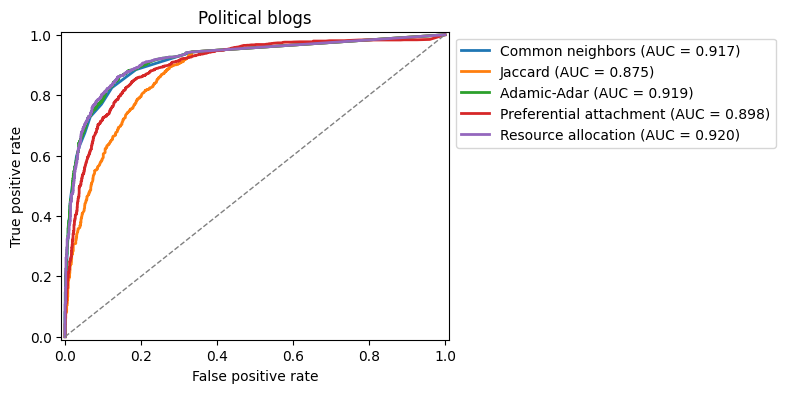

In [15]:
# ensure_connected=False because checking for bridges after every removal is too slow on a network this size
G_observed, test_edges, test_non_edges = train_test_split_graph(G_blogs, test_frac=0.1, seed=SEED,
                                                                ensure_connected=False)
n_test = len(test_edges)
print(f'{G_observed.number_of_edges()} edges left in G_observed, {n_test} hidden edges, {len(test_non_edges)} non-edges\n')

score_functions = {'Common neighbors': common_neighbors_score,
                   'Jaccard': jaccard_score,
                   'Adamic-Adar': adamic_adar_score,
                   'Preferential attachment': preferential_attachment_score,
                   'Resource allocation': resource_allocation_score}

score_dict, auc_dict = {}, {}
for name, fn in score_functions.items():
    y_test, score_dict[name], auc_dict[name] = evaluate_score_function(G_observed, test_edges, test_non_edges,
                                                                       fn, verbose=False)
    print(f'{name:24s} AUC = {auc_dict[name]:.3f}')

best_single = max(auc_dict.values())
plot_roc_curves(y_test, score_dict, 'Political blogs')

Very different from the BA graph! Just counting common neighbors gets us above 0.9, so any model we fit has a high bar to clear.

### Where do the training examples come from?

To fit a model, we need examples with answers: some pairs that are edges and some that aren't. Non-edges are easy to come by, but the edges take some thought. We can't use the test edges, since those stay hidden until the very end. And on the test, the model has to spot an edge it can't see in the graph, so we want it to practice on edges it can't see either.

So let's do the same trick again. We take `G_observed` and hide a *second* batch of edges, which leaves us with a smaller graph called `G_features`. We know the edges in this second batch are real, because we're the ones who hid them, so they can be our positive training examples.

| Graph | What's missing | Edges | What we use it for |
|---|---|---|---|
| `G_blogs` | Nothing | 16,714 | The full network, which is our answer key |
| `G_observed` | The 1,671 test edges | 15,043 | Computing scores for the **test** pairs |
| `G_features` | The 1,671 test edges and 1,671 training edges | 13,372 | Computing scores for the **training** pairs |

Notice that in both cases, the edge we're asking about is missing from the graph we compute its scores on. That's what makes the training examples look like the test. We'll see what happens if we skip this when we get to leakage.

In [16]:
features = {'common_neighbors': common_neighbors_score,
            'jaccard': jaccard_score,
            'adamic_adar': adamic_adar_score,
            'pref_attachment': preferential_attachment_score,
            'resource_allocation': resource_allocation_score}


def pair_features(G, pairs):
    '''One row per node pair, one column per score, with every score computed on the graph G.'''
    return pd.DataFrame({name: [fn(G, i, j) for (i, j) in pairs] for name, fn in features.items()})


def make_training_pairs(G, G_observed, test_non_edges, frac, seed):
    '''Hide a second batch of edges from G_observed, and pick as many non-edges of G that aren't in the test set.'''
    G_features, train_edges, _ = train_test_split_graph(G_observed, test_frac=frac, seed=seed, ensure_connected=False)
    non_edges = list(nx.non_edges(G))
    np.random.default_rng(seed).shuffle(non_edges)
    in_test = set(test_non_edges)
    train_non_edges = [pair for pair in non_edges if pair not in in_test][:len(train_edges)]
    return G_features, train_edges, train_non_edges


# A ninth of what's left in G_observed is another 10% of the original edges
G_features, train_edges, train_non_edges = make_training_pairs(G_blogs, G_observed, test_non_edges, 1 / 9, SEED + 1)

train_pairs = train_edges + train_non_edges
test_pairs = test_edges + test_non_edges
y_train = np.array([1] * len(train_edges) + [0] * len(train_non_edges))

X_train = pair_features(G_features, train_pairs)
X_test = pair_features(G_observed, test_pairs)

print(f'{len(train_pairs)} training pairs, {len(test_pairs)} test pairs')
X_train.assign(label=y_train).sample(5, random_state=SEED).round(3)

3342 training pairs, 3342 test pairs


,common_neighbors,jaccard,adamic_adar,pref_attachment,resource_allocation,label
479,1.0,0.015,0.434,195.0,0.100,1
1338,7.0,0.060,1.503,1140.0,0.071,1
705,6.0,0.092,1.358,1170.0,0.077,1
2550,0.0,0.000,0.000,0.0,0.000,0
2768,0.0,0.000,0.000,100.0,0.000,0


Each row is one pair of nodes. The five score columns are computed on `G_features`, and `label` is the answer: 1 if the pair is one of the edges we hid, 0 if it's a non-edge. We picked 1,671 of each, so the training table is half edges and half non-edges.

These five rows already show what the model has to work with. The three hidden edges have 1, 7, and 6 common neighbors, even though the edge itself is gone, and the two non-edges have none. Across the whole table, 94% of the hidden edges have at least one common neighbor, compared with 31% of the non-edges.

The signal still makes mistakes. About a third of the non-edges share a neighbor, and the last row has a preferential attachment score of 100 without being an edge. So let's see whether combining the scores does better than any one of them.

### Fitting a model

So far we've used each score on its own: pick one, rank the pairs by it, and see how good that ranking is. But we have five scores for every pair, and each one picks up something a little different. Can a model combine them into one better prediction?

We'll try two kinds of models that combine features in very different ways. **Logistic regression** adds the features up, giving each one a weight. A **decision tree** asks a series of yes-or-no questions about them.

### Logistic regression

In Class 6 we predicted fish weight with a weighted sum of the features, $\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$. We'd like to do the same thing here, but that sum can come out as any number, and our label is 0 or 1. What we really want is the probability that a pair is an edge. Logistic regression takes the same weighted sum and squashes it to be between 0 and 1:

$$
P(\text{edge} \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_p x_p)}}
$$

Here $x_1, \dots, x_p$ are the five scores for a node pair and the $\beta$s are the weights the model learns. If the weighted sum equals 0, the model says 0.5. If it's large and positive, the model says something close to 1, and if it's large and negative, something close to 0. Fitting means finding the $\beta$s that give the hidden edges high probabilities and the non-edges low ones.

Before we fit it, we get the features ready in two steps:

1. **Take the log of the count-like scores.** These scores are very skewed. For preferential attachment, the median training pair scores 561 and the largest scores 46,750. In a weighted sum, a pair's contribution grows in direct proportion to its score, so those few enormous values would dominate. We replace each score $x$ with $\log(1 + x)$, which turns 561 into about 6.3 and 46,750 into about 10.8. The $1 +$ is there because many pairs score 0, and $\log 0$ is undefined. We leave Jaccard alone, since it's already between 0 and 1.
2. **Put every column on the same scale.** `StandardScaler` rescales each column to have mean 0 and standard deviation 1, so that the weights can be compared with each other.

`make_pipeline` chains the scaler and the model together, so the scaler only ever learns from the training data and then reuses what it learned on the test data.

In [17]:
COUNT_COLUMNS = ['common_neighbors', 'adamic_adar', 'pref_attachment', 'resource_allocation', 'walks_3']


def log_counts(X):
    '''Take log(1 + x) of the count-like columns.'''
    X = X.copy()
    for col in X.columns:
        if col in COUNT_COLUMNS:
            X[col] = np.log1p(X[col])
    return X


logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
logit.fit(log_counts(X_train), y_train)
p_logit = logit.predict_proba(log_counts(X_test))[:, 1]     # second column: the probability of label 1

print(f'Best single score:   {best_single:.3f}')
print(f'Logistic regression: {roc_auc_score(y_test, p_logit):.3f}\n')
print(pd.Series(logit[-1].coef_[0], index=X_train.columns).round(2).to_string())

Best single score:   0.920
Logistic regression: 0.924

common_neighbors       1.81
jaccard               -0.62
adamic_adar            0.19
pref_attachment        0.79
resource_allocation    0.78


The first two lines are the test results: logistic regression gets 0.924, a little better than the best single score. The logs aren't doing much of that. Without them the model gets 0.922, so they make only a small difference here. We keep them because these scores are so skewed.

The list below that is the weight the model gave each score. Since we rescaled the columns, each weight says how much the weighted sum moves when that score goes up by one standard deviation and the others stay put. Positive weights push toward "edge" and negative weights push toward "no edge". Be careful with those coefficients though. Common neighbors and Adamic-Adar are almost the same column, and resource allocation is closely related, so the model can shove weight around between them without changing its predictions much.

### Decision trees

In logistic regression, each score pushes the weighted sum up or down by its own fixed amount, no matter what the other scores say. So it can't learn a rule like "preferential attachment only matters when two nodes share few neighbors."

A decision tree can. It's a sequence of yes-or-no questions about the features. Starting with all of the training pairs, it looks for the one question (a feature and a cutoff) that best separates the edges from the non-edges. That splits the pairs into two groups, and it repeats the search inside each group.

A tree only cares whether a value is above or below a cutoff, so it doesn't need logs or rescaling, which is why we can hand it plain `X_train`. Trees can get very complicated, but we can force them to limit their depth. Here's one that only gets two levels of questions.

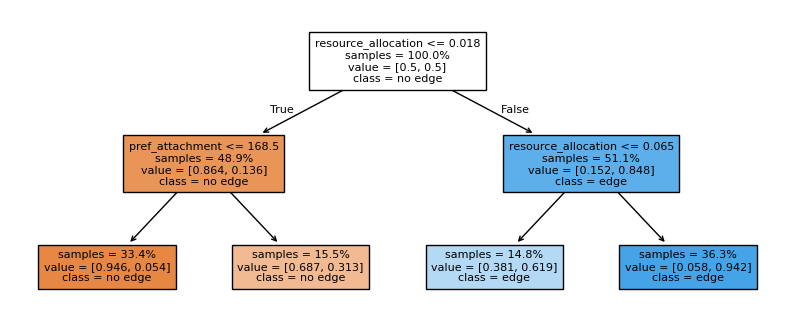

Depth-2 tree: 0.908


In [18]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(X_train, y_train)

fig, ax = plt.subplots(1, 1, figsize=(10, 4), dpi=100)
plot_tree(small_tree, feature_names=list(X_train.columns), class_names=['no edge', 'edge'], filled=True,
          impurity=False, proportion=True, fontsize=8, ax=ax)
plt.show()

print(f'Depth-2 tree: {roc_auc_score(y_test, small_tree.predict_proba(X_test)[:, 1]):.3f}')

### Reading the tree

Start at the top box and work your way down. Every box shows the same few things:

| In the box | What it means |
|---|---|
| `resource_allocation <= 0.018` | The question. If the answer is yes, the pair goes left (**True**). If it's no, the pair goes right (**False**). The bottom boxes have no question, because that's where pairs stop. They're called **leaves**. |
| `samples` | The share of the training pairs that reach this box |
| `value` | Among those pairs, the share that are `[no edge, edge]` |
| `class` | The tree's answer if it stopped here, which is whichever is more common. The top box is a 50/50 tie, so its "no edge" doesn't mean anything. |
| Color | Orange leans "no edge" and blue leans "edge". Darker means more lopsided. |

Let's follow two pairs down the tree. A pair with resource allocation above 0.065 goes right twice and lands in the dark blue leaf. That's where 36.3% of the training pairs ended up, and 94.2% of them are edges, so the tree gives any new pair landing there a 0.942 probability of being an edge. A pair with resource allocation of at most 0.018 and preferential attachment of at most 168.5 goes left twice. That leaf holds 33.4% of the training pairs, and only 5.4% of them are edges.

Notice that the tree asks a different second question on each side. When resource allocation is low, it checks preferential attachment, and when it's high, it asks about resource allocation again. A weighted sum can't do that. With only two levels of questions, it gets 0.908 on the test, a bit below the best single score.

### Hyperparameters

We picked two levels, but why two? A tree's questions and cutoffs are **parameters**: the model learns them from the data, just like the $\beta$s in logistic regression. Its maximum depth is different. We set it before fitting, and fitting doesn't change it. Settings like that are called **hyperparameters**. A deeper tree can ask more questions and carve the training data into smaller and smaller groups, so this choice matters.

We still don't want to use our test set to see how well we're doing when we change hyperparameters. Instead, we'll add another split to the dataset, known as the **validation set**. While we compare settings, the model **never** trains on the validation data, and it never trains on the test data at all. We use the validation set to figure out which hyperparameters work best, refit on all of the training data with those settings, and use the test set to figure out how well the final model does.

Below, we set aside 30% of the training table for validation (1,003 pairs). For each depth, we fit a tree on the other 70% (2,339 pairs) and score it on both groups.

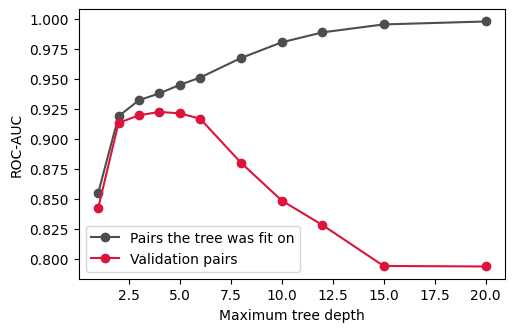

In [19]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.3, random_state=SEED, stratify=y_train)

depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
auc_fit, auc_val = [], []
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_fit, y_fit)
    auc_fit.append(roc_auc_score(y_fit, tree.predict_proba(X_fit)[:, 1]))
    auc_val.append(roc_auc_score(y_val, tree.predict_proba(X_val)[:, 1]))

fig, ax = plt.subplots(1, 1, figsize=(5.5, 3.5), dpi=100)
ax.plot(depths, auc_fit, 'o-', color='.3', label='Pairs the tree was fit on')
ax.plot(depths, auc_val, 'o-', color='crimson', label='Validation pairs')
ax.set_xlabel('Maximum tree depth')
ax.set_ylabel('ROC-AUC')
ax.legend()
plt.show()

### Overfitting

There's our overfitting, the problem from the start of class. The score on the pairs the tree was fit on keeps climbing, from 0.855 at depth 1 to 0.998 at depth 20. The score on the validation pairs goes up until depth 4, where it reaches 0.923, and then falls to 0.794. More questions always help on pairs the tree has already seen, but past a certain point they stop helping on new ones. The depth-20 tree has 323 leaves for 2,339 pairs, or about 7 pairs per leaf, so many of its rules describe a handful of particular pairs and nothing more general. Those deep trees are memorizing the windshield smudges.

So what do we do about it?

1. **Don't judge a model on the data it was fit on.** The gray line would tell us to pick the deepest tree, and the red line shows that would be a bad choice.
2. **Limit how complicated the model can get.** Here that means choosing the depth where the validation score peaks.
3. **Refit, then test once.** With the depth chosen, we refit on all of the training data and use the test set one time to report how well the final model does.

### Your turn!

Use `auc_val` to pick a depth. Refit a tree at that depth on all of `X_train`, and only *then* compute its ROC-AUC on the test set. How does it compare to the best single score?

In [20]:
# Your code here

Don't look below until you've tried it!

_______

In [21]:
best_depth = depths[int(np.argmax(auc_val))]
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED).fit(X_train, y_train)
print(f'Chosen depth: {best_depth}')
print(f'Test ROC-AUC: {roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]):.3f}   (best single score: {best_single:.3f})')

Chosen depth: 4
Test ROC-AUC: 0.922   (best single score: 0.920)


The depth-4 tree gets 0.922, about level with logistic regression and the best single score.

### Random forests

We just saw the trouble with a single tree. If it's deep, it memorizes the training pairs, and if it's shallow, it can only ask a few questions. A **random forest** (Breiman, 2001) grows many deep trees and averages their predictions. Each tree overfits in its own way, and averaging cancels out a lot of those mistakes.

If every tree saw the same data, every tree would come out the same, so the forest makes them different in two ways:

1. **Each tree gets its own random sample of the training pairs.** We draw 3,342 pairs from our 3,342 training pairs *with replacement*, so some pairs show up several times and others don't show up at all. On average, a tree sees about 63% of the distinct pairs.
2. **Each question can only use some of the features.** Every time a tree looks for its next question, it gets 2 of our 5 scores, chosen at random, and has to find the best question it can with those two. The strongest score is only available 40% of the time, so the trees can't all keep asking the same thing.

To score a new pair, each tree sends it down to a leaf and reports the share of edges in that leaf. The forest's prediction is the average of those 200 numbers.

Here's what the settings in `make_forest` do:

| Setting | What it does |
|---|---|
| `n_estimators=200` | Grow 200 trees. |
| `min_samples_leaf=5` | Every leaf has to hold at least 5 training pairs, so no tree makes a rule from fewer than that. |
| `random_state=SEED` | Use the same random draws every time we run this. |
| `n_jobs=-1` | Use all of the computer's cores. |

The first two are hyperparameters. We didn't set a maximum depth, so the trees get deep: about 17 levels and 160 leaves on average. Like the single tree, the forest doesn't need logs or rescaling.

We'll also give the models something the network structure doesn't have. We know each blog's politics, so `same_party` is a new column that's 1 if the two blogs are on the same side and 0 if they aren't.

In [22]:
def make_forest():
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)


def add_same_party(X, pairs):
    X = X.copy()
    X['same_party'] = [int(party[i] == party[j]) for (i, j) in pairs]
    return X


forest = make_forest().fit(X_train, y_train)
p_forest = forest.predict_proba(X_test)[:, 1]

X_train_party, X_test_party = add_same_party(X_train, train_pairs), add_same_party(X_test, test_pairs)
logit_party = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(log_counts(X_train_party), y_train)
forest_party = make_forest().fit(X_train_party, y_train)

print(f'Best single score:                    {best_single:.3f}')
print(f'Logistic regression:                  {roc_auc_score(y_test, p_logit):.3f}')
print(f'Random forest:                        {roc_auc_score(y_test, p_forest):.3f}')
print(f'Logistic regression with same_party:  {roc_auc_score(y_test, logit_party.predict_proba(log_counts(X_test_party))[:, 1]):.3f}')
print(f'Random forest with same_party:        {roc_auc_score(y_test, forest_party.predict_proba(X_test_party)[:, 1]):.3f}')

Best single score:                    0.920
Logistic regression:                  0.924
Random forest:                        0.927
Logistic regression with same_party:  0.934
Random forest with same_party:        0.937


The first line is our baseline. The forest gets 0.927, which is better than any of the trees inside it. On their own, its 200 trees average 0.888 on the test set, and the best one gets 0.901. It doesn't take many trees to get most of the benefit: 1 tree gets 0.886, 5 trees get 0.922, and 50 trees get 0.927.

Still, on the five scores alone, fitting a model buys us very little. We reran this on 10 different random splits, and both models beat the best single score every time, but on average only by about 0.004 (logistic regression) and 0.007 (random forest). These baselines are strong on this network! The five scores also mostly say the same thing. They're all built from the two nodes' neighbors, and the rank correlation (Spearman) between any two of them is at least 0.74. For common neighbors and Adamic-Adar it's 1.00.

The last two lines add `same_party`, which is new information. In the test set, 91% of the hidden edges connect blogs on the same side, compared with 49% of the non-edges. That helps more, about 0.014 and 0.016 over the best single score. The model works out how much weight the new column deserves, which we'd have to decide ourselves with a hand-written formula.

## What can go wrong? Leakage

Wait a second though. `G_observed` is full of edges, so why did we go to the trouble of hiding a second batch?

Let's try using the edges in `G_observed` as our positive examples, and let's add a feature that sounds perfectly reasonable: the shortest-path distance between the two nodes. We'll call this the **shortcut**.

To check our work without touching the test set, we'll use **cross-validation**. It's the validation set idea again, repeated so that every training pair gets a turn. We cut the training table into 5 parts, called **folds**, fit on 4 of them, score on the fifth, rotate through all 5, and average the scores.

The table below has one row for each combination of two choices: shortcut or hidden edges, and with or without the distance feature. `cross-validation AUC` is how well we think the model is doing, and `test AUC` is how well it does on the real test. If those two numbers are far apart, something is wrong.

In [23]:
def add_distance(X, G, pairs):
    '''Add the shortest-path distance in G between the two nodes of each pair (10 if unreachable).'''
    lengths = dict(nx.all_pairs_shortest_path_length(G))
    X = X.copy()
    X['distance'] = [lengths[i].get(j, 10) for (i, j) in pairs]
    return X


# The shortcut: positive examples are edges that are still in the graph
observed_edges = list(G_observed.edges())
picks = np.random.default_rng(SEED).choice(len(observed_edges), size=len(train_edges), replace=False)
shortcut_pairs = [observed_edges[t] for t in picks] + train_non_edges
X_shortcut = add_distance(pair_features(G_observed, shortcut_pairs), G_observed, shortcut_pairs)

# What we did above: positive examples are hidden from the graph their features come from
X_hidden = add_distance(X_train, G_features, train_pairs)
X_test_dist = add_distance(X_test, G_observed, test_pairs)
scores_only = list(X_train.columns)

rows = {}
for name, X_tr in [('Shortcut, with distance', X_shortcut),
                   ('Hidden edges, with distance', X_hidden),
                   ('Shortcut, five scores only', X_shortcut[scores_only]),
                   ('Hidden edges, five scores only', X_hidden[scores_only])]:
    cv_auc = cross_val_score(make_forest(), X_tr, y_train, cv=5, scoring='roc_auc').mean()
    model = make_forest().fit(X_tr, y_train)
    rows[name] = {'cross-validation AUC': cv_auc,
                  'test AUC': roc_auc_score(y_test, model.predict_proba(X_test_dist[list(X_tr.columns)])[:, 1])}

print(pd.DataFrame(rows).T.round(3).to_string())
print(f"\nCommon neighbors alone, test AUC: {auc_dict['Common neighbors']:.3f}")

                                cross-validation AUC  test AUC
Shortcut, with distance                        1.000     0.895
Hidden edges, with distance                    0.933     0.929
Shortcut, five scores only                     0.933     0.920
Hidden edges, five scores only                 0.932     0.927

Common neighbors alone, test AUC: 0.917


In [24]:
print('Distance between the two nodes, for the positive examples')
print('  shortcut training pairs:', X_shortcut['distance'][y_train == 1].value_counts().sort_index().to_dict())
print('  hidden training pairs:  ', X_hidden['distance'][y_train == 1].value_counts().sort_index().to_dict())
print('  test pairs:             ', X_test_dist['distance'][y_test == 1].value_counts().sort_index().to_dict())

Distance between the two nodes, for the positive examples
  shortcut training pairs: {1: 1671}
  hidden training pairs:   {2: 1564, 3: 88, 4: 4, 10: 15}
  test pairs:              {2: 1576, 3: 64, 4: 3, 10: 28}


Look at the first row. Cross-validation says the shortcut model is perfect, and then on the real test it loses to just counting common neighbors!

The distance counts tell us why. Every shortcut positive is an edge in the graph, so its distance is 1, and every non-edge has distance at least 2. So the model learned "distance 1 means edge". But a hidden edge is never at distance 1, because we removed it. This is called **leakage**: during training, the model gets information that won't be there when it has to make real predictions. Cross-validation can't catch it, because every fold has the same problem.

Two of our five scores leak as well. A pair's own edge adds to both nodes' degrees and neighbor sets, which changes Jaccard and preferential attachment. The other three only count shared neighbors, and a pair's own edge can't create one of those. That leak is small. Compare the last two rows: over 10 random splits, the shortcut came in below the hidden-edge model every time, by about 0.005 on average. With distance in the model, the gap is about 0.03.

When we build training examples for link prediction, we should **compute each pair's features as if its own edge weren't there**. The same rule applies to graph neural networks, where the edges kept in the graph are often called *message-passing edges* and the hidden training edges are often called *supervision edges*.

## Would this get harder if we looked at all possible links?

So far our test set has one non-edge for every hidden edge, and nobody actually has that problem. If someone handed us `G_observed` and asked for the missing links, we'd have to rank **every** pair that isn't connected. And in practice nobody reads a list that long. A recommender shows you a handful of suggestions, and a biologist can afford to test a few dozen candidate interactions. So precision@$k$ is back, along with a couple of other measures:

| Measure | Definition |
|---|---|
| Precision | What fraction of the pairs we called edges really are edges? |
| Recall | What fraction of the real edges did we find? |
| Precision@$k$ | Take the top $k$ pairs in the ranking. What fraction of them are real edges? |
| Average precision (AP) | Walk down the ranking, and every time we hit a real edge, write down the precision so far. Then average those numbers. |

Here's a small AP example. Say there are three real edges, and they land at positions 1, 3, and 6 in our ranking. The precision at those points is $1/1$, $2/3$, and $3/6$, so AP is $(1 + 0.67 + 0.5)/3 = 0.72$. AP is high when the real edges are near the top. A random ranking gets an AP of about the share of pairs that are real edges.

Let's keep the models we already fit and rank all the unconnected pairs, leaving out only the non-edges the models trained on.

In [25]:
hidden = {frozenset(pair) for pair in test_edges}
seen_in_training = {frozenset(pair) for pair in train_non_edges}

candidates = [pair for pair in nx.non_edges(G_observed) if frozenset(pair) not in seen_in_training]
y_all = np.array([int(frozenset(pair) in hidden) for pair in candidates])
X_all = pair_features(G_observed, candidates)

print(f'{len(candidates)} pairs to rank, of which {y_all.sum()} are hidden edges')
print(f'{(y_all == 0).sum() / y_all.sum():.0f} non-edges for every hidden edge')

729317 pairs to rank, of which 1671 are hidden edges
435 non-edges for every hidden edge


That's ten times worse than the 44 non-edges per edge we computed for the whole network, because we only hid a tenth of the edges and every non-edge is still in the running.

The next table compares five rankings: three of our scores and the two models. We don't refit anything. These are the models we trained on the half-and-half table, and now we're asking them to score far more pairs.

| Column | What it measures |
|---|---|
| `AUC, balanced` | ROC-AUC on the test set we've been using, with one non-edge per hidden edge |
| `AUC, all pairs` | ROC-AUC on all 729,317 candidate pairs |
| `AP, balanced` | Average precision on that same one-to-one test set. A random ranking gets about 0.5. |
| `AP, all pairs` | Average precision on all the candidate pairs. A random ranking gets about 0.002. |
| `Precision@100` | Of the 100 candidate pairs ranked highest, the share that are hidden edges |

In [26]:
balanced = {'Common neighbors': X_test['common_neighbors'],
            'Adamic-Adar': X_test['adamic_adar'],
            'Resource allocation': X_test['resource_allocation'],
            'Logistic regression': p_logit,
            'Random forest': p_forest}

rankings = {'Common neighbors': X_all['common_neighbors'].to_numpy(),
            'Adamic-Adar': X_all['adamic_adar'].to_numpy(),
            'Resource allocation': X_all['resource_allocation'].to_numpy(),
            'Logistic regression': logit.predict_proba(log_counts(X_all))[:, 1],
            'Random forest': forest.predict_proba(X_all)[:, 1]}

table = pd.DataFrame({name: {'AUC, balanced': roc_auc_score(y_test, balanced[name]),
                             'AUC, all pairs': roc_auc_score(y_all, s),
                             'AP, balanced': average_precision_score(y_test, balanced[name]),
                             'AP, all pairs': average_precision_score(y_all, s),
                             'Precision@100': precision_at_k(y_all, s, 100)}
                      for name, s in rankings.items()}).T

print(f'A random ranking has precision {y_all.mean():.4f}\n')
print(table.round(3).to_string())

A random ranking has precision 0.0023

                     AUC, balanced  AUC, all pairs  AP, balanced  AP, all pairs  Precision@100
Common neighbors             0.917           0.914         0.912          0.099           0.43
Adamic-Adar                  0.919           0.917         0.921          0.098           0.38
Resource allocation          0.920           0.918         0.921          0.079           0.29
Logistic regression          0.924           0.922         0.930          0.079           0.28
Random forest                0.927           0.925         0.925          0.067           0.14


Start with the two AUC columns. They barely move, even with hundreds of non-edges per hidden edge. ROC-AUC asks how often a random hidden edge outranks a random non-edge, and the answer doesn't depend on how many non-edges there are.

Average precision drops from above 0.9 to below 0.1. Common neighbors shows us why. About half of the hidden edges (877) have at least 10 common neighbors, and only 2.3% of the non-edges do, which is why the AUC looks so good. But 2.3% of 727,646 non-edges is 16,805 pairs. If we called every pair with at least 10 common neighbors an edge, about 19 out of every 20 would be wrong. An AP below 0.1 is still way better than the 0.002 a random ranking would get.

Now look at the last column. Common neighbors gets 0.43, so 43 of its top 100 pairs are hidden edges. A random list of 100 pairs would have about 0.2. Those 43 are only 2.6% of the 1,671 hidden edges, so the recall is low, and that's fine if we only have time to check 100 pairs.

The fitted models have the best ROC-AUC, and common neighbors and Adamic-Adar still beat them at the top of the list! We reran this on 10 random splits, and neither model beat common neighbors on precision@100 or on average precision in any of them. On average, common neighbors gets a precision@100 of about 0.45, logistic regression 0.27, and the random forest 0.15.

Two things help explain this. First, our models were trained on a table that's half edges, and they were trained to do well across all of those pairs. Nobody told them that edges are rare or that we only care about the top of the list. Logistic regression gives more than 110,000 of these pairs a probability above 0.5, and only 1,442 of those are hidden edges. Second, the forest runs out of ways to tell its best pairs apart. It gives 1,439 pairs a score of exactly 1.0, and 238 of them (17%) are hidden edges. Its top 100 is an arbitrary slice of that tied group, so its 0.14 is about what we'd get by picking 100 of those pairs at random.

Training with 20 non-edges per edge gets logistic regression to about 0.29 and the random forest to about 0.26, which helps, but neither catches common neighbors in any of the 10 splits.

Which model is best depends on whether you care about the whole ranking or only the top of it.

Let's look at the non-edges that common neighbors ranks highest.

In [27]:
# The non-edges that common neighbors likes the most
order = np.argsort(-X_all['common_neighbors'].to_numpy())
top_mistakes = [t for t in order if y_all[t] == 0][:8]
side = {0: 'liberal', 1: 'conservative'}
for t in top_mistakes:
    i, j = candidates[t]
    print(f"{int(X_all['common_neighbors'].iloc[t]):3d} shared   {blog_name[i]} ({side[party[i]]})  /  {blog_name[j]} ({side[party[j]]})")

106 shared   blogsforbush.com (conservative)  /  instapundit.com (conservative)
 85 shared   dailykos.com (liberal)  /  yglesias.typepad.com/matthew (liberal)
 84 shared   blogsforbush.com (conservative)  /  michellemalkin.com (conservative)
 81 shared   blogsforbush.com (conservative)  /  powerlineblog.com (conservative)
 79 shared   drudgereport.com (conservative)  /  michellemalkin.com (conservative)
 77 shared   dailykos.com (liberal)  /  oliverwillis.com (liberal)
 77 shared   blogsforbush.com (conservative)  /  wizbangblog.com (conservative)
 73 shared   drudgereport.com (conservative)  /  powerlineblog.com (conservative)


These are prominent blogs, paired with others on their own side, that share a huge number of neighbors and just don't link to each other in this data. If this were a missing-link problem, this is the list we'd go check first.

-------

## When local heuristics fail: a disassortative SBM

Common neighbors, Jaccard, Adamic-Adar, and resource allocation all make the same bet: two nodes with a lot of neighbors in common are likely to be connected. That's a kind of **homophily**, the idea that similar nodes connect. It worked well on the blogs, where 91% of the hidden edges connect blogs on the same side.

What happens on a network where that bet is wrong? Let's build one with the stochastic block model (SBM) from Class 9. We'll use two groups of 40 nodes. Two nodes in the same group connect with probability 0.02, and two nodes in different groups connect with probability 0.15. Most edges run between the groups, which is what **disassortative** means.

In [28]:
# Disassortative SBM
sizes = [40, 40]
# p[r][s] is the probability of an edge between a node in group r and a node in group s:
# 0.02 inside a group, 0.15 across groups
p = [[0.02, 0.15],
     [0.15, 0.02]]

G_sbm = nx.stochastic_block_model(sizes, p, seed=SEED)

G_sbm_train, test_sbm, neg_sbm = train_test_split_graph(
    G_sbm, test_frac=0.2, seed=SEED, ensure_connected=True
)

print("SBM (disassortative)")
print("  Nodes:", G_sbm.number_of_nodes())
print("  Edges:", G_sbm.number_of_edges())
print("  Test positives:", len(test_sbm))
print("  Test negatives:", len(neg_sbm))

SBM (disassortative)
  Nodes: 80
  Edges: 284
  Test positives: 56
  Test negatives: 56


Of the 284 edges, 260 (92%) run between the two groups. We hid 56 of them for testing and picked 56 non-edges to compare them with. Here's what the network looks like.

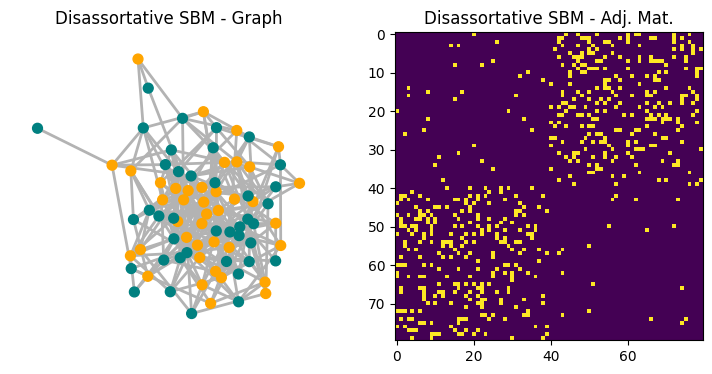

In [29]:
fig, ax = plt.subplots(1,2,figsize=(9,4),dpi=100)

# Left: the graph, colored by group. Right: the adjacency matrix (nodes 0-39 are one group, 40-79 the other)
nx.draw(G_sbm,pos=nx.spring_layout(G_sbm, seed=SEED),node_size=50,width=2,edge_color='.7',
        node_color=['orange']*40+['teal']*40,ax=ax[0])
ax[1].imshow(nx.to_numpy_array(G_sbm))

ax[0].set_title('Disassortative SBM - Graph')
ax[1].set_title('Disassortative SBM - Adj. Mat.')

plt.show()

On the left, orange and teal are the two groups. They're all mixed together, because the layout puts nodes near the nodes they link to, and those are mostly in the other group.

The right panel is easier to read. It's the adjacency matrix, with a yellow square wherever two nodes are connected. Nodes 0 to 39 are one group and nodes 40 to 79 are the other. The top-left and bottom-right blocks are the within-group pairs, and they're nearly empty. The other two blocks are the between-group pairs, and that's where the edges are.

Before you run the next cell, think about which pairs will share the most neighbors: two nodes in the same group, or two nodes in different groups? Then let's see how our five scores do.

In [30]:
# Same five scores, now on the disassortative SBM
results = {}
for name, fn in [
    ("Common neighbors", common_neighbors_score),
    ("Jaccard", jaccard_score),
    ("Adamic-Adar", adamic_adar_score),
    ("Preferential attachment", preferential_attachment_score),
    ("Resource allocation", resource_allocation_score),
]:
    y, s, auc = evaluate_score_function(G_sbm_train, test_sbm, neg_sbm, fn, verbose=False)
    results[name] = (y, s, auc)

for name, (y, s, auc) in results.items():
    print(f"{name:23s}: SBM ROC-AUC = {auc:.3f}")

Common neighbors       : SBM ROC-AUC = 0.371
Jaccard                : SBM ROC-AUC = 0.370
Adamic-Adar            : SBM ROC-AUC = 0.363
Preferential attachment: SBM ROC-AUC = 0.538
Resource allocation    : SBM ROC-AUC = 0.363


The four neighborhood scores get an AUC *below* 0.5, so they do worse than random guessing. They tend to rank non-edges above hidden edges. Preferential attachment is close to 0.5. This network is small, so the exact numbers bounce around, but if you change `SEED` and rerun, the neighborhood scores stay below 0.5 about nine times in ten. Over seeds 0 to 99, the common-neighbors AUC averages about 0.43.

Here's why. Take two nodes in the **same** group. Each of them links to a lot of nodes in the other group, so they have many chances to share a neighbor, and they rarely link to each other. Now take two nodes in **different** groups. They link to each other often, but any neighbor they share needs a within-group edge to one of them, and those are rare. In the graph we computed these scores on, same-group pairs share 0.67 neighbors on average and different-group pairs share 0.13.

So common neighbors puts same-group pairs at the top of its ranking, and 53 of our 56 hidden edges are between groups. The score still carries information, and it's pointing the wrong way. If we flipped its sign, its AUC would go from 0.37 to 0.63.

A model that learns the group structure gets this right; Appendix H of Class 9 does link prediction with an SBM fit in `graph-tool`. Each link prediction method encodes an assumption about how edges form, and it does badly on networks where that assumption is wrong.

### Homophily vs. heterophily

**Homophily** means similar nodes are more likely to connect, and **heterophily** means dissimilar nodes are more likely to connect. Common neighbors and Jaccard work well on the first kind of network and struggle on the second. There, we may need different predictors or extra information, such as node attributes.

Some papers that take such features into account: [Zheng et al., 2022](https://arxiv.org/abs/2202.07082), [Zhu et al., 2021](https://arxiv.org/abs/2009.13566), and [Kovács et al., 2019](https://www.nature.com/articles/s41467-019-09177-y).

Kovács et al. (2019) ran into exactly this in protein interaction networks. Two proteins that share many partners are not more likely to interact, because similar proteins tend to bind the same targets rather than each other. So common neighbors fails there for the same reason as in our SBM. They score a pair by the number of paths of length three between them instead (degree-normalized; they call it L3).

![](images/proteins.png)

### Can a model figure this out on its own?

So far, more common neighbors has always meant a higher score. Logistic regression can give a feature a negative weight, so it can learn from the training pairs that here, *fewer* common neighbors means an edge is more likely. But a model can only use what's in its columns, so let's also give it two new ones. Both are designed to tell us whether two nodes are on opposite sides.

**Walks of length 3.** $[A^3]_{ij}$ counts the walks of length 3 from $i$ to $j$. Most edges cross between the groups, so a typical walk switches sides at every step, and after three steps it's on the opposite side from where it started. That means this count should be large for pairs on opposite sides. In these networks it averages 4.3 for pairs in different groups and 1.3 for pairs in the same group. It's the same idea as L3, without the degree normalization.

**Which side is each node on?** Remember from Class 4 that a bipartite graph has $-\lambda_{\max}$ as an eigenvalue (that's why the scores on the path graph kept flipping back and forth). The eigenvector for that eigenvalue is positive on one side and negative on the other. Our SBM has a few within-group edges, so it's only nearly bipartite, but the same idea works. Let $x$ be the eigenvector of its most negative eigenvalue. The sign of $x_i$ tells us which side node $i$ is on, and it gets about 96% of the nodes right using nothing but the network.

The feature for a pair is $-x_i x_j$. If the two nodes are on opposite sides, $x_i$ and $x_j$ have opposite signs, so $-x_i x_j$ is positive. If they're on the same side, it's negative. On average it's $0.70$ for pairs in different groups and $-0.69$ for pairs in the same group. The overall sign of an eigenvector is arbitrary, and flipping it changes the sign of both $x_i$ and $x_j$, so this product doesn't care.

With 80 nodes, one network is a noisy test, so let's repeat the whole thing on 100 networks: hide test edges, hide training edges, compute features, fit, score. In the code, `sbm_features` adds the two new columns, `fit_and_score` fits logistic regression on whichever columns we name, and `sbm_experiment` does all of this for one network.

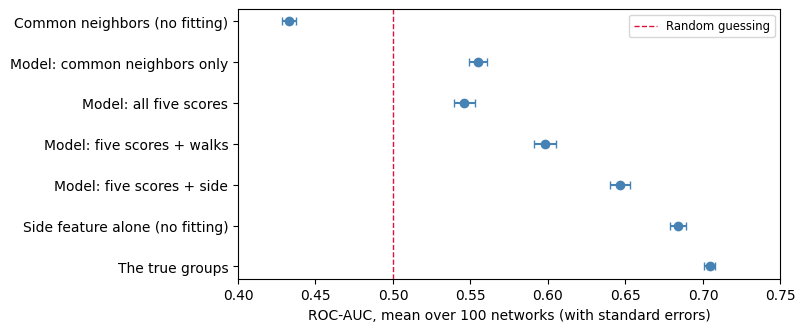

Common neighbors (no fitting)      0.433
Model: common neighbors only       0.555
Model: all five scores             0.546
Model: five scores + walks         0.598
Model: five scores + side          0.647
Side feature alone (no fitting)    0.684
The true groups                    0.704

The coefficient on common neighbors is negative in 92% of the networks
Average number of positive training edges per network: 54


In [31]:
def sbm_features(G_graph, pairs):
    '''The five scores, plus walks of length 3 and the side feature.'''
    A = nx.to_numpy_array(G_graph, nodelist=sorted(G_graph.nodes()))
    walks = A @ A @ A
    eigenvalues, eigenvectors = np.linalg.eigh(A)      # eigenvalues come back in increasing order
    x = eigenvectors[:, 0] * np.sqrt(len(A))           # the most negative one, scaled to typical size 1
    X = pair_features(G_graph, pairs)
    X['walks_3'] = [walks[i, j] for (i, j) in pairs]
    X['side'] = [-x[i] * x[j] for (i, j) in pairs]
    return X


def fit_and_score(X_tr, y_tr, X_te, y_te, columns):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    model.fit(log_counts(X_tr[columns]), y_tr)
    return roc_auc_score(y_te, model.predict_proba(log_counts(X_te[columns]))[:, 1]), model[-1].coef_[0]


def sbm_experiment(seed):
    G_s = nx.stochastic_block_model(sizes, p, seed=seed)
    G_obs, te_edges, te_non = train_test_split_graph(G_s, test_frac=0.2, seed=seed, ensure_connected=False)
    G_feat, tr_edges, tr_non = make_training_pairs(G_s, G_obs, te_non, 1 / 4, seed + 1000)
    y_tr = np.array([1] * len(tr_edges) + [0] * len(tr_non))
    y_te = np.array([1] * len(te_edges) + [0] * len(te_non))
    X_tr = sbm_features(G_feat, tr_edges + tr_non)
    X_te = sbm_features(G_obs, te_edges + te_non)
    five = list(features)

    auc_cn, coef_cn = fit_and_score(X_tr, y_tr, X_te, y_te, ['common_neighbors'])
    different_group = [int((i < sizes[0]) != (j < sizes[0])) for (i, j) in te_edges + te_non]
    return {'Common neighbors (no fitting)': roc_auc_score(y_te, X_te['common_neighbors']),
            'Model: common neighbors only': auc_cn,
            'Model: all five scores': fit_and_score(X_tr, y_tr, X_te, y_te, five)[0],
            'Model: five scores + walks': fit_and_score(X_tr, y_tr, X_te, y_te, five + ['walks_3'])[0],
            'Model: five scores + side': fit_and_score(X_tr, y_tr, X_te, y_te, five + ['side'])[0],
            'Side feature alone (no fitting)': roc_auc_score(y_te, X_te['side']),
            'The true groups': roc_auc_score(y_te, different_group),
            'coef': coef_cn[0], 'n_train_edges': len(tr_edges)}


sbm_results = pd.DataFrame([sbm_experiment(s) for s in range(100)])
coefs = sbm_results.pop('coef')
n_train_edges = sbm_results.pop('n_train_edges')
means, errors = sbm_results.mean(), sbm_results.sem()

fig, ax = plt.subplots(1, 1, figsize=(7, 3.5), dpi=100)
ax.errorbar(means, range(len(means))[::-1], xerr=errors, fmt='o', color='steelblue', capsize=3)
ax.set_yticks(range(len(means))[::-1])
ax.set_yticklabels(means.index)
ax.axvline(0.5, color='crimson', ls='--', lw=1, label='Random guessing')
ax.set_xlim(0.4, 0.75)
ax.set_xlabel('ROC-AUC, mean over 100 networks (with standard errors)')
ax.legend(fontsize='small', loc='upper right')
plt.show()

print(means.round(3).to_string())
print(f'\nThe coefficient on common neighbors is negative in {(coefs < 0).mean():.0%} of the networks')
print(f'Average number of positive training edges per network: {n_train_edges.mean():.0f}')

Each dot is one approach, averaged over 100 networks, and anything to the right of the dashed line beats random guessing. Let's go from top to bottom.

Common neighbors on its own gets 0.433, below 0.5, like we saw. Give a model that exact same column and it gets 0.555. It learned a negative coefficient in 92% of these networks, so it picked the direction from the training pairs, which a fixed formula can't do.

Giving it all five scores doesn't help (0.546). Adding walks to the five scores gets us to about 0.60, and adding the side feature instead gets us to about 0.65. The side feature all by itself gets 0.684, which beats the model that has it along with the five scores. We only have about 54 positive training edges per network, so those extra weak columns mostly add noise to the fit.

The last row is the ceiling. Once you know the groups, every edge in this model is an independent coin flip, so nothing can do better than ranking between-group pairs above within-group pairs. That gets 0.704, and the side feature, computed from the network alone, gets close to it.

That side feature gave each node one number describing where it sits in the network. That's a tiny **embedding**, and we had to work out by hand which number to use. On Monday we let the model learn these numbers itself.

Today we fit models on top of hand-built scores. Much of the recent work learns the whole score from data instead. Random-walk embeddings such as DeepWalk and node2vec learn a vector for each node by treating short random walks like sentences (Perozzi et al., 2014; Grover and Leskovec, 2016). Graph neural networks such as GCNs and GATs learn how to combine information from a node's neighbors (Kipf and Welling, 2017; Veličković et al., 2018; Hamilton et al., 2017). We'll start on these ideas on Monday. There is also work on stacking many predictors into one, which comes close to the best achievable performance across hundreds of real networks (Ghasemian et al., 2020), and on methods built for heterogeneous or heterophilous graphs (Dong et al., 2017; Wang et al., 2019; Fu et al., 2020; Zheng et al., 2022; Zhu et al., 2021). The references below are a good place to start.

__________
## Next time...
Machine Learning 2: Graph ML & GNNs `class_19_machine_learning2.ipynb` (Mon, Nov 23)
_______

## References and further resources:

1. Class Webpages
    - Jupyter Book: https://computational-methods-network-science.github.io/nets7052_fa26/README.html
    - Github: https://github.com/computational-methods-network-science/nets7052_fa26/
    - Syllabus and course details: https://brennanklein.com/nets7052-fall26
2. Adamic, L. A., & Adar, E. (2003). Friends and neighbors on the web. *Social Networks*, 25(3), 211–230. https://doi.org/10.1016/S0378-8733(03)00009-1
3. Al Hasan, M., Chaoji, V., Salem, S., & Zaki, M. (2006). Link prediction using supervised learning. In *SDM'06 Workshop on Link Analysis, Counter-terrorism and Security*.
4. Albert, R., & Barabási, A.-L. (2002). Statistical mechanics of complex networks. *Reviews of Modern Physics*, 74(1), 47–97. https://doi.org/10.1103/RevModPhys.74.47
5. Barabási, A.-L., Jeong, H., Néda, Z., Ravasz, E., Schubert, A., & Vicsek, T. (2002). Evolution of the social network of scientific collaborations. *Physica A*, 311(3–4), 590–614. https://doi.org/10.1016/S0378-4371(02)00736-7
6. Clauset, A., Moore, C., & Newman, M. E. J. (2008). Hierarchical structure and the prediction of missing links in networks. *Nature*, 453(7191), 98–101. https://doi.org/10.1038/nature06830
7. Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, 27(8), 861–874. https://doi.org/10.1016/j.patrec.2005.10.010
8. Kovács, I. A., Luck, K., Spirohn, K., Wang, Y., Pollis, C., Schlabach, S., Bian, W., Kim, D.-K., Kishore, N., Hao, T., Calderwood, M. A., Vidal, M., & Barabási, A.-L. (2019). Network-based prediction of protein interactions. *Nature Communications*, 10, 1240. https://doi.org/10.1038/s41467-019-09177-y
9. Liben-Nowell, D., & Kleinberg, J. (2007). The link-prediction problem for social networks. *Journal of the American Society for Information Science and Technology*, 58(7), 1019–1031. https://doi.org/10.1002/asi.20591
10. Lü, L., & Zhou, T. (2011). Link prediction in complex networks: A survey. *Physica A: Statistical Mechanics and its Applications*, 390(6), 1150–1170. https://doi.org/10.1016/j.physa.2010.11.027
11. Newman, M. E. J. (2001). Clustering and preferential attachment in growing networks. *Physical Review E*, 64(2), 025102. https://doi.org/10.1103/PhysRevE.64.025102
12. Newman, M. E. J. (2018). *Networks* (2nd ed.). Oxford University Press.
13. Zhou, T., Lü, L., & Zhang, Y.-C. (2009). Predicting missing links via local information. *The European Physical Journal B*, 71(4), 623–630. https://doi.org/10.1140/epjb/e2009-00335-8
14. Ghasemian, A., Hosseinmardi, H., Galstyan, A., Airoldi, E. M., & Clauset, A. (2020). Stacking models for nearly optimal link prediction in complex networks. *Proceedings of the National Academy of Sciences of the United States of America*, 117(38), 23393–23400. https://doi.org/10.1073/pnas.1914950117
15. Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). DeepWalk: Online learning of social representations. In *Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’14)* (pp. 701–710). https://doi.org/10.1145/2623330.2623732
16. Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’16)* (pp. 855–864). https://doi.org/10.1145/2939672.2939754
17. Veličković, P., Cucurull, G., Casanova, A., Romero, A., Liò, P., & Bengio, Y. (2018). Graph attention networks. In *International Conference on Learning Representations (ICLR 2018)*. arXiv:1710.10903. https://arxiv.org/abs/1710.10903
18. Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. In *International Conference on Learning Representations (ICLR 2017)*. arXiv:1609.02907. https://arxiv.org/abs/1609.02907
19. Hamilton, W. L., Ying, R., & Leskovec, J. (2017). Inductive representation learning on large graphs. In *Advances in Neural Information Processing Systems (NeurIPS 2017)* (pp. 1025–1035). arXiv:1706.02216. https://arxiv.org/abs/1706.02216
20. Dong, Y., Chawla, N. V., & Swami, A. (2017). metapath2vec: Scalable representation learning for heterogeneous networks. In *Proceedings of the 23rd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD ’17)* (pp. 135–144). https://doi.org/10.1145/3097983.3098036
21. Wang, X., Ji, H., Shi, C., Wang, B., Ye, Y., Cui, P., & Yu, P. S. (2019). Heterogeneous graph attention network. In *Proceedings of the World Wide Web Conference (WWW 2019)* (pp. 2022–2032). https://doi.org/10.1145/3308558.3313562
22. Fu, X., Zhang, J., Meng, Z., & King, I. (2020). MAGNN: Metapath aggregated graph neural network for heterogeneous graph embedding. In *Proceedings of the Web Conference 2020 (WWW ’20)* (pp. 2331–2341). https://doi.org/10.1145/3366423.3380297
23. Zheng, X., Wang, Y., Liu, Y., Li, M., Zhang, M., Jin, D., Yu, P. S., & Pan, S. (2022). Graph neural networks for graphs with heterophily: A survey. *arXiv preprint* arXiv:2202.07082. https://arxiv.org/abs/2202.07082
24. Zhu, J., Rossi, R. A., Rao, A., Mai, T., Lipka, N., Ahmed, N. K., & Koutra, D. (2021). Graph neural networks with heterophily. *Proceedings of the AAAI Conference on Artificial Intelligence*, 35(12), 11168–11176. https://doi.org/10.1609/aaai.v35i12.17332
25. Adamic, L. A., & Glance, N. (2005). The political blogosphere and the 2004 US election: Divided they blog. In *Proceedings of the 3rd International Workshop on Link Discovery* (pp. 36–43). https://doi.org/10.1145/1134271.1134277
26. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324